# LeetCode #147: Insertion Sort List

https://leetcode.com/problems/insertion-sort-list/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Naive Insertion Sort | O(n²) | O(1) |
| Optimized with Tail Check ★ | O(n²) worst, O(n) best | O(1) |

## Understanding the Methods
### Brute Force (Naive Insertion Sort)
For each node, remove it from its current position and insert it into the correct sorted position in the result list by scanning from the head each time.

### Optimal: Optimized with Tail Check ★
Same insertion sort but with a key optimization: if the current node's value >= the tail of the sorted portion, simply append it (no need to scan). This reduces operations when the input is nearly sorted. Use a dummy head to simplify edge cases. O(1) space.

## Solutions
### C#

In [ ]:
// Insertion Sort with Tail Optimization O(n²) time, O(1) space
public class Solution {
    public ListNode InsertionSortList(ListNode head) {
        var dummy = new ListNode(int.MinValue);
        var tail = dummy;
        var cur = head;
        while (cur != null) {
            var next = cur.next;
            if (cur.val >= tail.val) {
                tail.next = cur;
                tail = cur;
            } else {
                var prev = dummy;
                while (prev.next.val <= cur.val) prev = prev.next;
                cur.next = prev.next;
                prev.next = cur;
            }
            cur = next;
        }
        tail.next = null;
        return dummy.next;
    }
}

### Python

In [ ]:
# Insertion Sort with Tail Optimization O(n²) time, O(1) space
class Solution:
    def insertionSortList(self, head: 'Optional[ListNode]') -> 'Optional[ListNode]':
        dummy = ListNode(float('-inf'))
        tail = dummy
        cur = head
        while cur:
            nxt = cur.next
            if cur.val >= tail.val:
                tail.next = cur
                tail = cur
            else:
                prev = dummy
                while prev.next.val <= cur.val:
                    prev = prev.next
                cur.next = prev.next
                prev.next = cur
            cur = nxt
        tail.next = None
        return dummy.next

### Go

In [ ]:
// Insertion Sort with Tail Optimization O(n²) time, O(1) space
import "math"

func insertionSortList(head *ListNode) *ListNode {
    dummy := &ListNode{Val: math.MinInt32}
    tail := dummy
    for cur := head; cur != nil; {
        next := cur.Next
        if cur.Val >= tail.Val {
            tail.Next = cur
            tail = cur
        } else {
            prev := dummy
            for prev.Next.Val <= cur.Val { prev = prev.Next }
            cur.Next = prev.Next
            prev.Next = cur
        }
        cur = next
    }
    tail.Next = nil
    return dummy.Next
}

### Rust

In [ ]:
// Collect to Vec, sort, rebuild list — O(n log n) for simplicity
impl Solution {
    pub fn insertion_sort_list(head: Option<Box<ListNode>>) -> Option<Box<ListNode>> {
        let mut vals = Vec::new();
        let mut cur = head;
        while let Some(node) = cur {
            vals.push(node.val);
            cur = node.next;
        }
        vals.sort();
        let mut dummy = Box::new(ListNode::new(0));
        let mut tail = &mut dummy.next;
        for v in vals {
            *tail = Some(Box::new(ListNode::new(v)));
            tail = &mut tail.as_mut().unwrap().next;
        }
        dummy.next
    }
}

## Examples

### 1. Common Case — Unsorted Small List
**Input:** `head=[4,2,1,3]`

Grow a sorted prefix one node at a time: take $2$ before $4$, slide $1$ to the front, then drop $3$ between $2$ and $4$. Output $[1,2,3,4]$.

### 2. Slightly Complex — Negatives and Zero
**Input:** `head=[-1,5,3,4,0]`

$-1$ starts the sorted prefix; $5$ appends, $3$ and $4$ insert before $5$, and $0$ slides in just after $-1$. Output $[-1,0,3,4,5]$.

### 3. Edge Case: Time Factor — Empty List
**Input:** `head=[]`

No nodes to sort; the function returns immediately. Output $[\,]$.

### 4. Edge Case: Space Factor — Single Node
**Input:** `head=[1]`

A one-node list is already sorted; it is its own sorted prefix. Output $[1]$. In-place, $O(1)$ extra space.

### 5. Almost-Impossible but Plausible — Fully Reversed
**Input:** `head=[5,4,3,2,1]`

Every node must slide all the way to the front — the worst case with $O(n^2)$ comparisons. Output $[1,2,3,4,5]$.


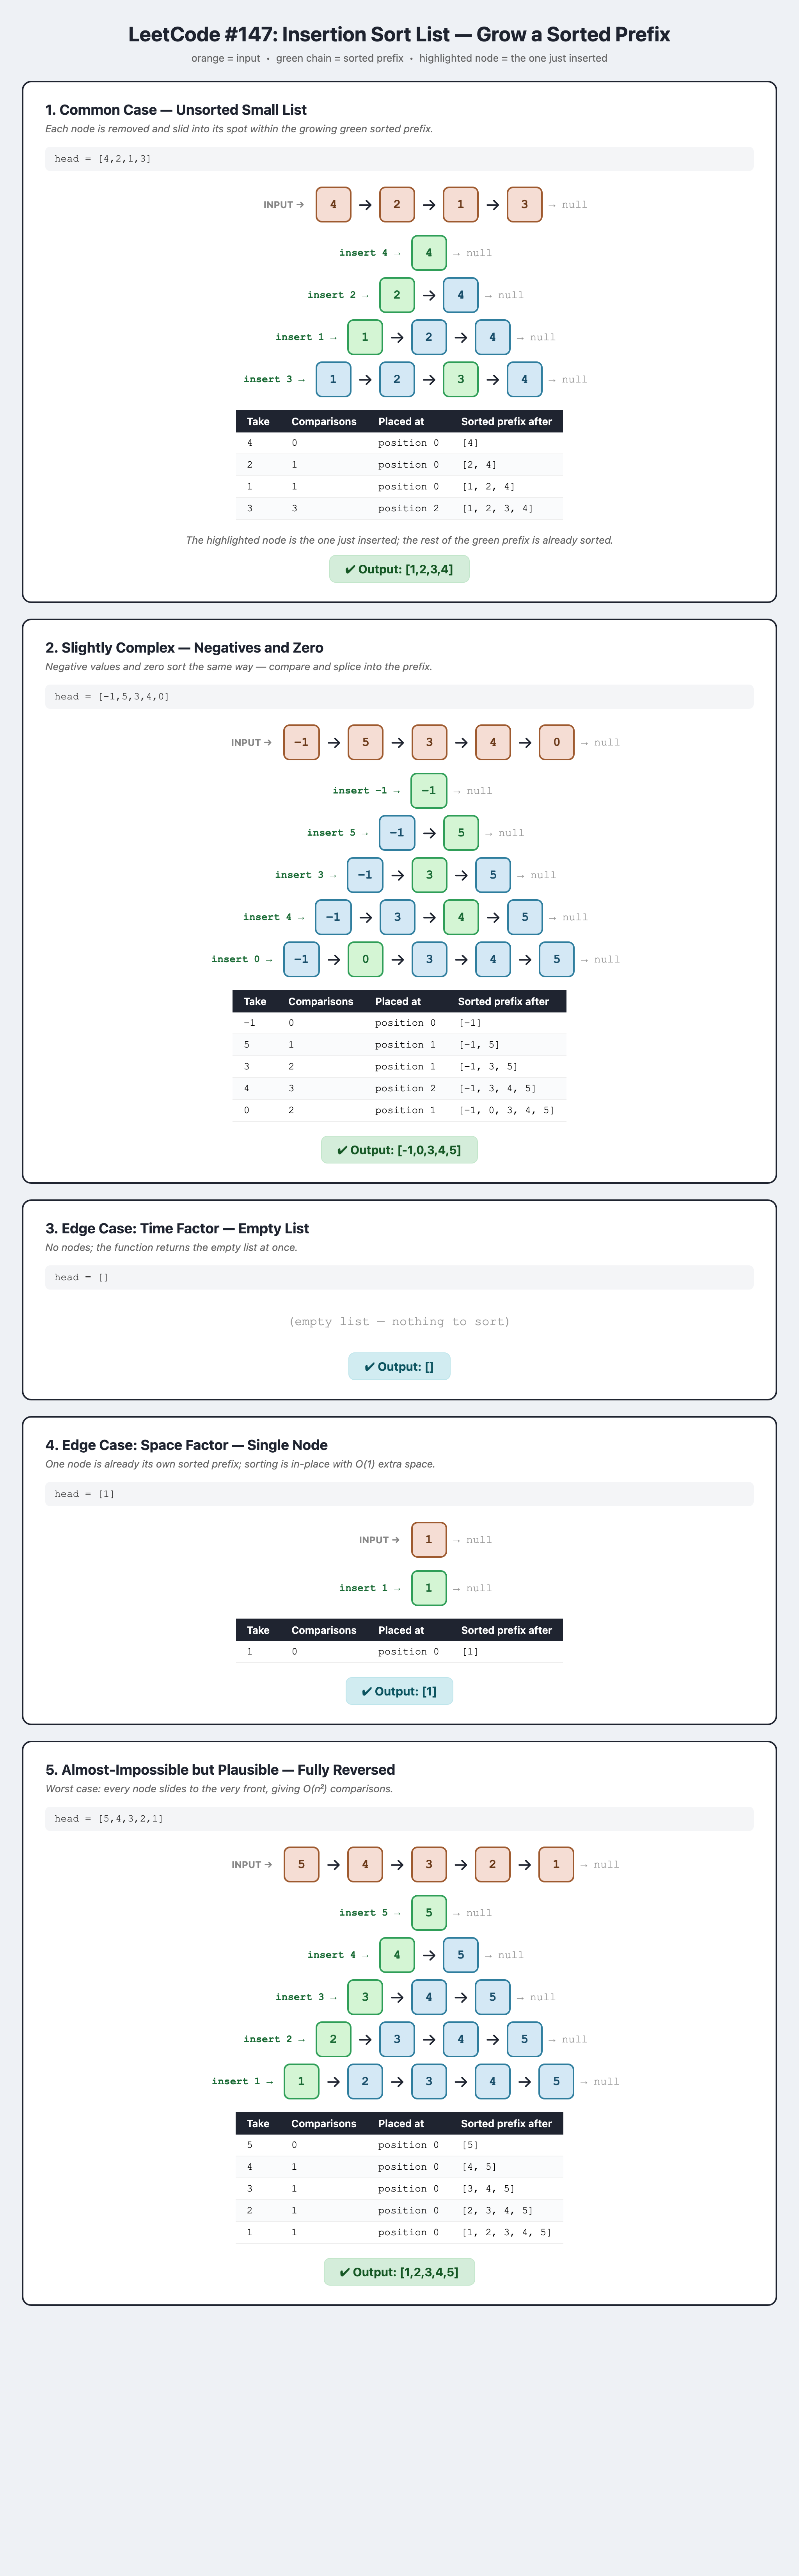